In [1]:
%pip install torch torchvision numpy matplotlib pandas scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\keert\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip


In [2]:
import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)

classes = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

train_full = datasets.FashionMNIST(
    root="data", train=True, download=True, transform=transform
)
test_data = datasets.FashionMNIST(
    root="data", train=False, download=True, transform=transform
)

train_data, val_data = random_split(
    train_full, [54000, 6000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))

Device: cpu
Training images: 54000
Validation images: 6000
Testing images: 10000


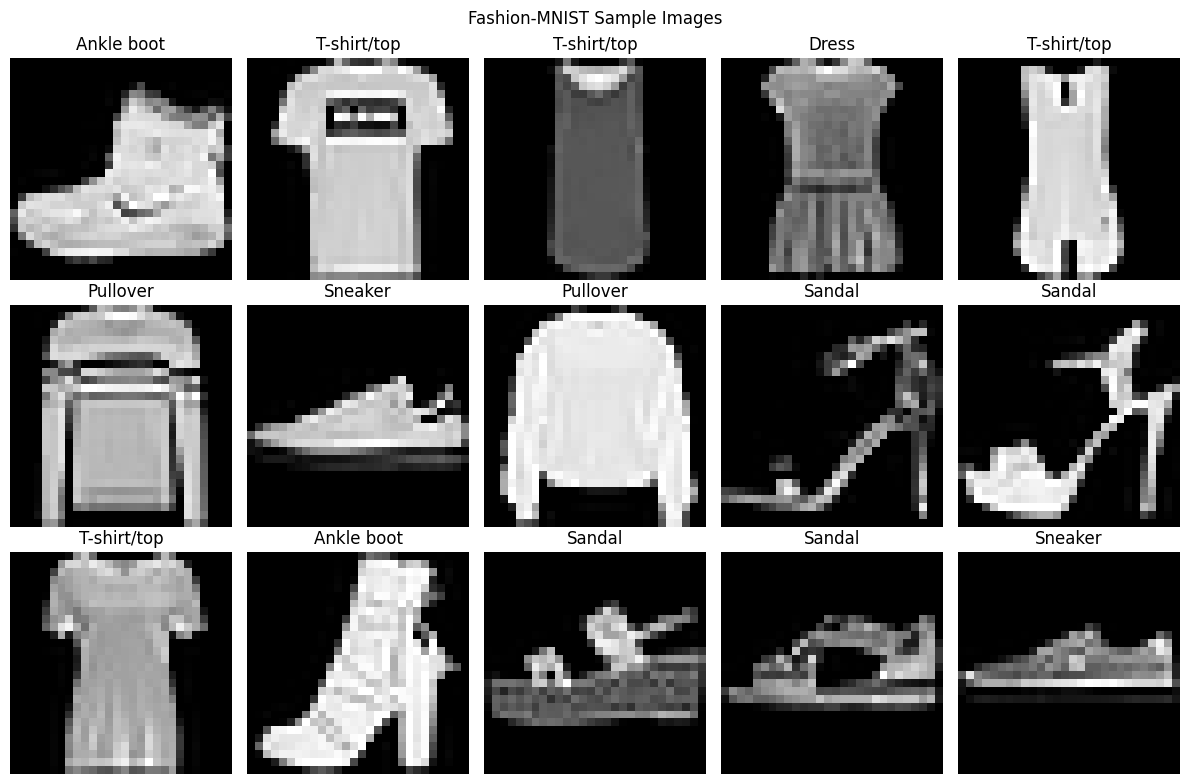

Image batch shape: torch.Size([64, 1, 28, 28])


In [3]:
def display_image(image):
    return (image * 0.3530 + 0.2860).squeeze().clamp(0, 1)

fig, axes = plt.subplots(3, 5, figsize=(12, 8))

for i, ax in enumerate(axes.flat):
    image, label = train_full[i]
    ax.imshow(display_image(image), cmap="gray")
    ax.set_title(classes[label])
    ax.axis("off")

plt.suptitle("Fashion-MNIST Sample Images")
plt.tight_layout()
plt.savefig("outputs/sample_images.png")
plt.show()

images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)

In [4]:
class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        return self.fc_layers(x)


cnn_model = CNNModel().to(device)
print(cnn_model)

CNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [5]:
class FullyConnectedModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.layers(x)


fc_model = FullyConnectedModel().to(device)
print(fc_model)

FullyConnectedModel(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [6]:
def train_model(model, model_name, epochs=5):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    best_val_loss = float("inf")
    start_time = time.time()

    for epoch in range(epochs):
       
        model.train()
        running_loss = 0
        correct = 0
        total = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            outputs = model(x)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * y.size(0)
            correct += (outputs.argmax(1) == y).sum().item()
            total += y.size(0)

        train_loss = running_loss / total
        train_acc = correct / total
        model.eval()
        val_running_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                outputs = model(x)
                loss = criterion(outputs, y)

                val_running_loss += loss.item() * y.size(0)
                val_correct += (outputs.argmax(1) == y).sum().item()
                val_total += y.size(0)

        val_loss = val_running_loss / val_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), f"models/{model_name}.pth")

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    history_df = pd.DataFrame(history)
    history_df.to_csv(f"outputs/{model_name}_history.csv", index=False)

    return history, time.time() - start_time
fc_history, fc_time = train_model(
    fc_model, "fully_connected", epochs=5
)
cnn_history, cnn_time = train_model(
    cnn_model, "fashion_cnn", epochs=5
)

Epoch 1/5 | Train Loss: 0.4685 | Val Loss: 0.3910 | Train Acc: 0.8280 | Val Acc: 0.8532
Epoch 2/5 | Train Loss: 0.3470 | Val Loss: 0.3907 | Train Acc: 0.8731 | Val Acc: 0.8583
Epoch 3/5 | Train Loss: 0.3129 | Val Loss: 0.3470 | Train Acc: 0.8839 | Val Acc: 0.8732
Epoch 4/5 | Train Loss: 0.2862 | Val Loss: 0.3358 | Train Acc: 0.8934 | Val Acc: 0.8777
Epoch 5/5 | Train Loss: 0.2698 | Val Loss: 0.3263 | Train Acc: 0.8988 | Val Acc: 0.8793
Epoch 1/5 | Train Loss: 0.4806 | Val Loss: 0.3244 | Train Acc: 0.8266 | Val Acc: 0.8835
Epoch 2/5 | Train Loss: 0.3085 | Val Loss: 0.2796 | Train Acc: 0.8885 | Val Acc: 0.8947
Epoch 3/5 | Train Loss: 0.2627 | Val Loss: 0.2511 | Train Acc: 0.9043 | Val Acc: 0.9052
Epoch 4/5 | Train Loss: 0.2306 | Val Loss: 0.2278 | Train Acc: 0.9163 | Val Acc: 0.9188
Epoch 5/5 | Train Loss: 0.2061 | Val Loss: 0.2308 | Train Acc: 0.9239 | Val Acc: 0.9175


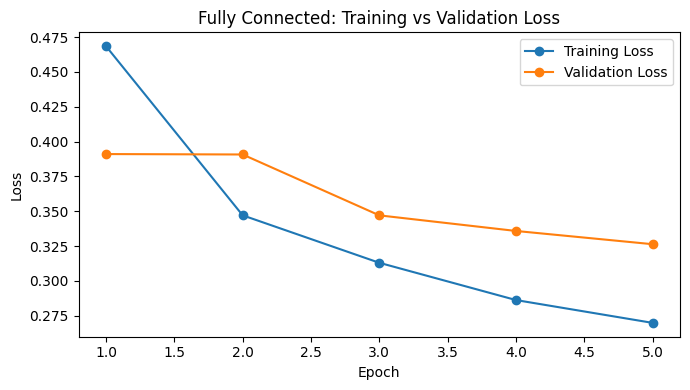

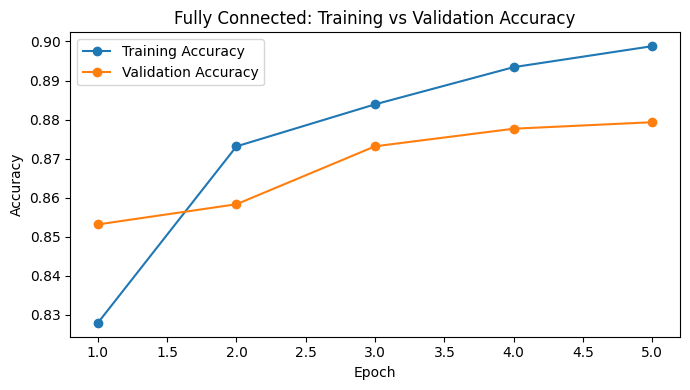

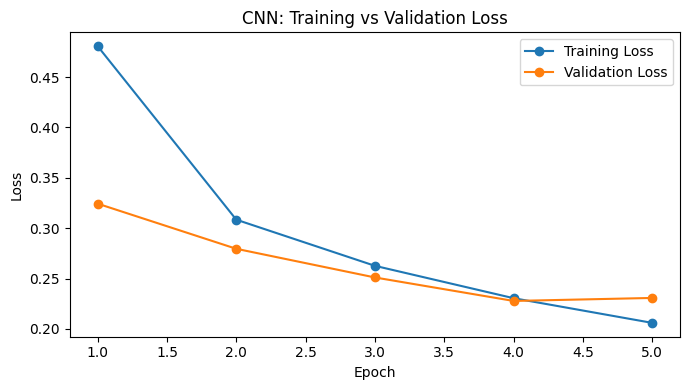

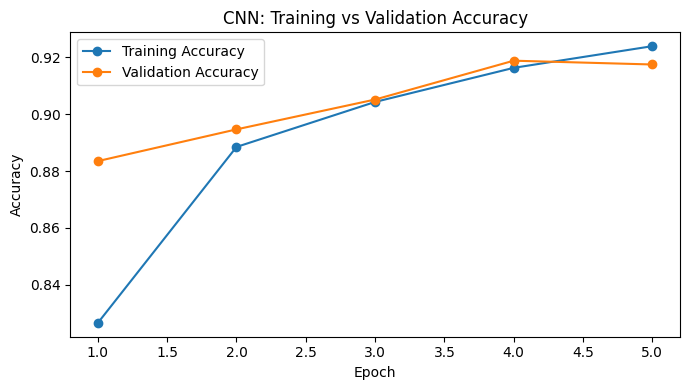

In [7]:
def plot_history(history, model_name):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
    plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{model_name}: Training vs Validation Loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"outputs/{model_name}_loss.png")
    plt.show()

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history["train_acc"], marker="o", label="Training Accuracy")
    plt.plot(epochs, history["val_acc"], marker="o", label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{model_name}: Training vs Validation Accuracy")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"outputs/{model_name}_accuracy.png")
    plt.show()


plot_history(fc_history, "Fully Connected")
plot_history(cnn_history, "CNN")

In [8]:
def evaluate_model(model):
    model.eval()
    criterion = nn.CrossEntropyLoss()

    all_predictions = []
    all_labels = []
    total_loss = 0
    total = 0

    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            loss = criterion(outputs, y)

            total_loss += loss.item() * y.size(0)
            total += y.size(0)

            predictions = outputs.argmax(1)
            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(y.cpu().numpy())

    test_loss = total_loss / total
    test_accuracy = np.mean(np.array(all_predictions) == np.array(all_labels))

    return test_loss, test_accuracy, all_labels, all_predictions


fc_loss, fc_acc, _, _ = evaluate_model(fc_model)
cnn_loss, cnn_acc, y_true, y_pred = evaluate_model(cnn_model)

print(f"Fully Connected Test Loss: {fc_loss:.4f}")
print(f"Fully Connected Test Accuracy: {fc_acc:.2%}")
print(f"CNN Test Loss: {cnn_loss:.4f}")
print(f"CNN Test Accuracy: {cnn_acc:.2%}")

print("\nCNN Classification Report:")
print(classification_report(
    y_true, y_pred, labels=list(range(10)),
    target_names=classes, zero_division=0
))

Fully Connected Test Loss: 0.3535
Fully Connected Test Accuracy: 87.46%
CNN Test Loss: 0.2375
CNN Test Accuracy: 91.50%

CNN Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.88      0.85      0.87      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.91      0.83      0.87      1000
       Dress       0.88      0.94      0.91      1000
        Coat       0.81      0.93      0.86      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.78      0.71      0.74      1000
     Sneaker       0.96      0.96      0.96      1000
         Bag       0.99      0.98      0.99      1000
  Ankle boot       0.96      0.97      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.91     10000
weighted avg       0.92      0.92      0.91     10000



             Model  Test Loss  Test Accuracy (%)  Training Time (seconds)  \
0  Fully Connected      0.353              87.46                  435.505   
1              CNN      0.238              91.50                 1027.807   

   Trainable Parameters  
0                235146  
1                421642  


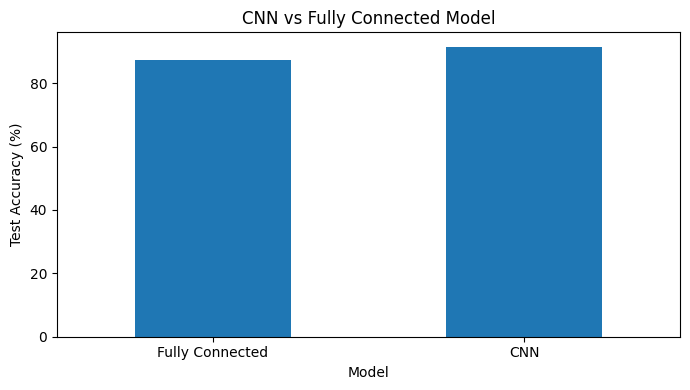

In [9]:
comparison = pd.DataFrame({
    "Model": ["Fully Connected", "CNN"],
    "Test Loss": [fc_loss, cnn_loss],
    "Test Accuracy (%)": [fc_acc * 100, cnn_acc * 100],
    "Training Time (seconds)": [fc_time, cnn_time],
    "Trainable Parameters": [
        sum(p.numel() for p in fc_model.parameters() if p.requires_grad),
        sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
    ]
})

print(comparison.round(3))
comparison.to_csv("outputs/model_comparison.csv", index=False)

comparison.plot(
    x="Model", y="Test Accuracy (%)",
    kind="bar", legend=False, figsize=(7, 4)
)
plt.ylabel("Test Accuracy (%)")
plt.title("CNN vs Fully Connected Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/model_comparison.png")
plt.show()

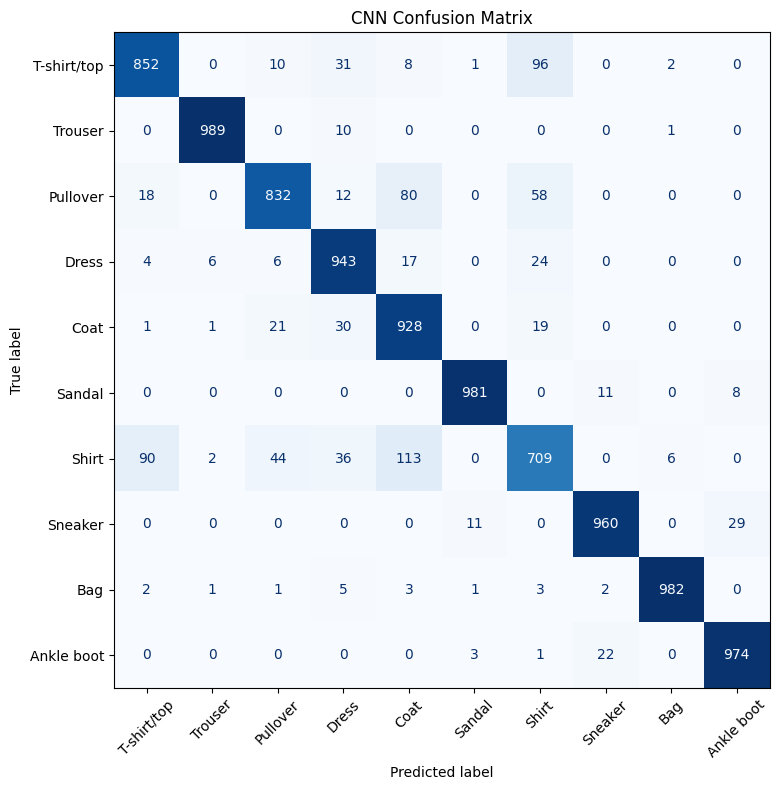

In [10]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=classes
)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png")
plt.show()

1. Actual: Sneaker, Predicted: Sandal, Confidence: 57.5%
Possible reason: the clothing items may have similar shapes or visual features, or the image may be ambiguous.

2. Actual: Ankle boot, Predicted: Sandal, Confidence: 98.6%
Possible reason: the clothing items may have similar shapes or visual features, or the image may be ambiguous.

3. Actual: Coat, Predicted: Pullover, Confidence: 70.5%
Possible reason: the clothing items may have similar shapes or visual features, or the image may be ambiguous.

4. Actual: Shirt, Predicted: T-shirt/top, Confidence: 75.8%
Possible reason: the clothing items may have similar shapes or visual features, or the image may be ambiguous.

5. Actual: Dress, Predicted: Shirt, Confidence: 51.0%
Possible reason: the clothing items may have similar shapes or visual features, or the image may be ambiguous.



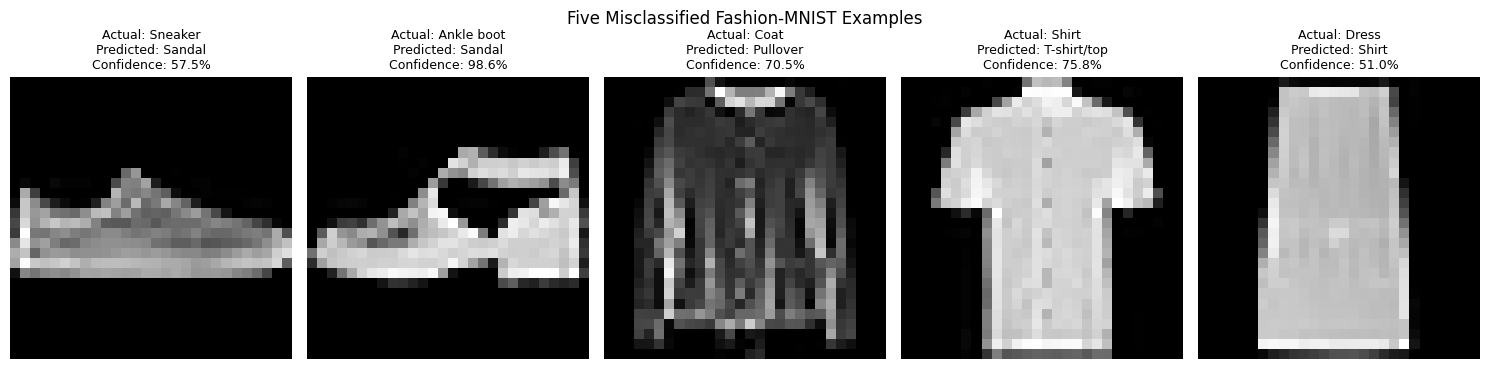

In [11]:
cnn_model.eval()
wrong_examples = []

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        outputs = cnn_model(x)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(1)

        wrong_indices = (predictions != y).nonzero(as_tuple=True)[0]

        for idx in wrong_indices:
            wrong_examples.append((
                x[idx].cpu(),
                y[idx].item(),
                predictions[idx].item(),
                probabilities[idx, predictions[idx]].item()
            ))

            if len(wrong_examples) == 5:
                break

        if len(wrong_examples) == 5:
            break

if not wrong_examples:
    print("No misclassified examples were found.")
else:
    fig, axes = plt.subplots(
        1, len(wrong_examples), figsize=(15, 4)
    )
    if len(wrong_examples) == 1:
        axes = [axes]

    for i, (image, true_label, pred_label, confidence) in enumerate(wrong_examples):
        axes[i].imshow(display_image(image), cmap="gray")
        axes[i].set_title(
            f"Actual: {classes[true_label]}\n"
            f"Predicted: {classes[pred_label]}\n"
            f"Confidence: {confidence:.1%}",
            fontsize=9
        )
        axes[i].axis("off")

        print(
            f"{i+1}. Actual: {classes[true_label]}, "
            f"Predicted: {classes[pred_label]}, "
            f"Confidence: {confidence:.1%}"
        )
        print(
            "Possible reason: the clothing items may have similar "
            "shapes or visual features, or the image may be ambiguous.\n"
        )

    plt.suptitle("Five Misclassified Fashion-MNIST Examples")
    plt.tight_layout()
    plt.savefig("outputs/misclassified_examples.png")
    plt.show()

In [12]:
cnn_model.load_state_dict(
    torch.load("models/fashion_cnn.pth", map_location=device)
)
cnn_model.eval()
image, label = test_data[0]

with torch.no_grad():
    output = cnn_model(image.unsqueeze(0).to(device))
    probabilities = torch.softmax(output, dim=1)
    predicted = output.argmax(1).item()

print("Actual class:", classes[label])
print("Predicted class:", classes[predicted])
print(f"Confidence: {probabilities[0, predicted].item():.2%}")
print("CNN model saved and reloaded successfully.")

Actual class: Ankle boot
Predicted class: Ankle boot
Confidence: 99.95%
CNN model saved and reloaded successfully.


C:\Users\keert\AppData\Local\Temp\ipykernel_14200\469955326.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load("models/fashion_cnn.pth", map_location=device)


In [13]:
print("ASSIGNMENT 3 COMPLETED")
print(f"CNN Test Accuracy: {cnn_acc:.2%}")
print(f"Fully Connected Test Accuracy: {fc_acc:.2%}")
print("Comparison table: outputs/model_comparison.csv")
print("Graphs and confusion matrix: outputs/")
print("Saved CNN model: models/fashion_cnn.pth")

ASSIGNMENT 3 COMPLETED
CNN Test Accuracy: 91.50%
Fully Connected Test Accuracy: 87.46%
Comparison table: outputs/model_comparison.csv
Graphs and confusion matrix: outputs/
Saved CNN model: models/fashion_cnn.pth
